# ElasticNet 80/20 smoke test

Place this notebook in the `new_pipeline_enet/` project root, beside `run_enet.sh`.

It loads the real `data/transcriptomics_filtered.joblib` and `data/proteomics_matched.joblib`, runs a tiny in-memory 80/20 ElasticNet test, displays metrics and model details, and does **not** save any H5 files.

In [1]:
# >>> pRNA figure routing (added by the pRNA update; keep as the first code cell)
# Every figure is shown inline. Every file written with savefig (png, pdf, svg) is redirected to
# figures_pdf/<notebook name>/ next to this notebook; sub-folders of the original path are preserved.
import os as _fig_os
from pathlib import Path as _FigPath
import matplotlib as _fig_mpl
import matplotlib.pyplot as _fig_plt
from matplotlib.figure import Figure as _FigFigure

NOTEBOOK_NAME = "enet_8020_smoke_test"
FIG_DIR = (_FigPath.cwd() / "figures_pdf" / NOTEBOOK_NAME).resolve()
FIG_DIR.mkdir(parents=True, exist_ok=True)


def _route_figure_path(fname):
    p = _FigPath(_fig_os.fspath(fname))
    full = p if p.is_absolute() else (_FigPath.cwd() / p)
    try:
        full.resolve().relative_to(FIG_DIR)
        return fname                                  # already inside this notebook's figure folder
    except ValueError:
        pass
    try:
        rel = _FigPath(_fig_os.path.relpath(full.resolve(), _FigPath.cwd()))
    except ValueError:                                # e.g. another drive on Windows
        rel = _FigPath(p.name)
    parts = [x for x in rel.parts if x not in ("..", ".", "figures_pdf", NOTEBOOK_NAME)]
    target = FIG_DIR.joinpath(*parts) if parts else FIG_DIR / p.name
    target.parent.mkdir(parents=True, exist_ok=True)
    return target


if not getattr(_FigFigure.savefig, "_prna_routed", False):
    _fig_orig_savefig = _FigFigure.savefig

    def _fig_routed_savefig(self, fname, *args, **kwargs):
        if isinstance(fname, (str, bytes, _FigPath)) or hasattr(fname, "__fspath__"):
            fname = _route_figure_path(fname)
        return _fig_orig_savefig(self, fname, *args, **kwargs)

    _fig_routed_savefig._prna_routed = True
    _FigFigure.savefig = _fig_routed_savefig

    _fig_orig_close = _fig_plt.close

    def _fig_close_and_show(fig=None):
        """Display figures that are closed before Jupyter could render them, then close."""
        import inspect as _fig_inspect
        _caller = _fig_inspect.currentframe().f_back
        _caller_mod = (_caller.f_globals.get("__name__", "") if _caller is not None else "")
        if _caller_mod.startswith(("matplotlib", "ipykernel")):   # backend housekeeping, not user code
            return _fig_orig_close(fig)
        if "inline" in str(_fig_mpl.get_backend()).lower():
            from IPython.display import display as _fig_display
            open_nums = set(_fig_plt.get_fignums())
            if fig is None:
                figs = [_fig_plt.gcf()] if open_nums else []
            elif isinstance(fig, str) and fig == "all":
                figs = [_fig_plt.figure(n) for n in sorted(open_nums)]
            elif isinstance(fig, _FigFigure):
                figs = [fig] if getattr(fig, "number", None) in open_nums else []
            elif isinstance(fig, int):
                figs = [_fig_plt.figure(fig)] if fig in open_nums else []
            else:
                figs = []
            for _f in figs:
                if not getattr(_f, "_prna_displayed", False):
                    _f._prna_displayed = True
                    _fig_display(_f)
        return _fig_orig_close(fig)

    _fig_plt.close = _fig_close_and_show

    _fig_orig_show = _fig_plt.show

    def _fig_show_and_mark(*args, **kwargs):
        for _n in _fig_plt.get_fignums():                    # shown now -> never re-displayed on close
            _fig_plt.figure(_n)._prna_displayed = True
        return _fig_orig_show(*args, **kwargs)

    _fig_plt.show = _fig_show_and_mark

print("Figures are saved to", FIG_DIR)

Figures are saved to C:\Users\hp\Desktop\CPPR\Cancer-Protein-RNA-research\02. elasticNet\new_pipeline_8020\figures_pdf\enet_8020_smoke_test


In [2]:
from pathlib import Path
import sys
import json

import numpy as np
import pandas as pd
from joblib import load
import matplotlib.pyplot as plt

PROJECT_DIR = Path.cwd().resolve()
SRC_DIR = PROJECT_DIR / 'src'
DATA_DIR = PROJECT_DIR.parent / 'data'

sys.path.insert(0, str(SRC_DIR))

from functions import (
    detect_protein_axis,
    run_enet_8020_for_protein,
    predict_with_artifact,
)

X_PATH = DATA_DIR / 'transcriptomics_filtered.joblib'
Y_PATH = DATA_DIR / 'proteomics_matched.joblib'

print('PROJECT_DIR:', PROJECT_DIR)
print('SRC_DIR:', SRC_DIR)
print('DATA_DIR:', DATA_DIR)
print('X_PATH exists:', X_PATH.exists(), X_PATH)
print('Y_PATH exists:', Y_PATH.exists(), Y_PATH)


PROJECT_DIR: C:\Users\hp\Desktop\CPPR\Cancer-Protein-RNA-research\02. elasticNet\new_pipeline_8020
SRC_DIR: C:\Users\hp\Desktop\CPPR\Cancer-Protein-RNA-research\02. elasticNet\new_pipeline_8020\src
DATA_DIR: C:\Users\hp\Desktop\CPPR\Cancer-Protein-RNA-research\02. elasticNet\data
X_PATH exists: True C:\Users\hp\Desktop\CPPR\Cancer-Protein-RNA-research\02. elasticNet\data\transcriptomics_filtered.joblib
Y_PATH exists: True C:\Users\hp\Desktop\CPPR\Cancer-Protein-RNA-research\02. elasticNet\data\proteomics_matched.joblib


In [3]:
X = load(X_PATH)
Y = load(Y_PATH)

print('Transcriptomics shape:', X.shape)
print('Proteomics shape:', Y.shape)
print('Transcriptomics index examples:', list(map(str, X.index[:3])))
print('Transcriptomics column examples:', list(map(str, X.columns[:3])))
print('Proteomics row examples:', list(map(str, Y.index[:3])))
print('Proteomics column examples:', list(map(str, Y.columns[:3])))

proteins, orientation, index_overlap, column_overlap = detect_protein_axis(X, Y)
print('Detected orientation:', orientation)
print('Sample overlap with Y.index:', index_overlap)
print('Sample overlap with Y.columns:', column_overlap)
print('Detected proteins:', len(proteins))
print('First proteins:', proteins[:5])


Transcriptomics shape: (369, 22614)
Proteomics shape: (369, 5113)
Transcriptomics index examples: ['MDAMB468_BREAST', 'SH4_SKIN', 'AU565_BREAST']
Transcriptomics column examples: ['A1BG', 'A1BG-AS1', 'A1CF']
Proteomics row examples: ['MDAMB468_BREAST', 'SH4_SKIN', 'AU565_BREAST']
Proteomics column examples: ['A2M', 'AAAS', 'AACS']
Detected orientation: samples_as_rows__proteins_as_columns
Sample overlap with Y.index: 369
Sample overlap with Y.columns: 0
Detected proteins: 5113
First proteins: ['A2M', 'AAAS', 'AACS', 'AAGAB', 'AAK1']


In [4]:
# Tiny smoke-test settings. These are intentionally small and do not save H5 outputs.
TEST_PROTEINS = proteins[:3]
NORMALIZATIONS = ['none', 'zscore', 'binning']

PARAM_GRID_TINY = {
    'alpha': [0.1, 1.0],
    'l1_ratio': [0.1, 0.9],
}

settings = dict(
    param_grid=PARAM_GRID_TINY,
    n_bins=50,
    select_k=50,
    test_size=0.2,
    n_splits=3,
    max_param_combos=2,
    enet_max_iter=5000,
    enet_tol=1e-3,
    enet_selection='random',
    fit_intercept=False,
    n_samples=40,
    h5_path=None,
)

print('Proteins:', TEST_PROTEINS)
print('Normalizations:', NORMALIZATIONS)
print('Settings:', settings)


Proteins: ['A2M', 'AAAS', 'AACS']
Normalizations: ['none', 'zscore', 'binning']
Settings: {'param_grid': {'alpha': [0.1, 1.0], 'l1_ratio': [0.1, 0.9]}, 'n_bins': 50, 'select_k': 50, 'test_size': 0.2, 'n_splits': 3, 'max_param_combos': 2, 'enet_max_iter': 5000, 'enet_tol': 0.001, 'enet_selection': 'random', 'fit_intercept': False, 'n_samples': 40, 'h5_path': None}


In [5]:
rows = []
results = {}

for protein in TEST_PROTEINS:
    for norm in NORMALIZATIONS:
        print('=' * 100)
        print('Running:', protein, norm)
        result = run_enet_8020_for_protein(
            X,
            Y,
            protein,
            normalization=norm,
            **settings,
        )
        results[(protein, norm)] = result
        m = result['metrics']
        artifact = result['model_artifact']
        rows.append({
            'protein': protein,
            'normalization': norm,
            'test_mse': m.get('test_mse'),
            'test_pearson_corr': m.get('test_pearson_corr'),
            'test_cosine_similarity': m.get('test_cosine_similarity'),
            'train_n': len(result['train_samples']),
            'test_n': len(result['test_samples']),
            'selected_features': len(result['selected_features']),
            'nonzero_coefficients': artifact.get('coef_nonzero_count'),
            'best_params': result['best_params'],
        })

summary = pd.DataFrame(rows)
summary


Running: A2M none
Running: A2M zscore
Running: A2M binning
Running: AAAS none
Running: AAAS zscore
Running: AAAS binning
Running: AACS none
Running: AACS zscore
Running: AACS binning


,protein,normalization,test_mse,test_pearson_corr,test_cosine_similarity,train_n,test_n,selected_features,nonzero_coefficients,best_params
0,A2M,none,1.024559,0.856993,0.839075,32,8,50,29,"{'alpha': 0.1, 'l1_ratio': 0.1, '_cv_mse': 1.0..."
1,A2M,zscore,1.840122,NaN,NaN,32,8,50,0,"{'alpha': 1.0, 'l1_ratio': 0.9, '_cv_mse': 1.0..."
2,A2M,binning,1.840122,NaN,NaN,32,8,50,0,"{'alpha': 1.0, 'l1_ratio': 0.9, '_cv_mse': 1.0..."
3,AAAS,none,0.094860,NaN,NaN,32,8,50,0,"{'alpha': 1.0, 'l1_ratio': 0.9, '_cv_mse': 0.1..."
4,AAAS,zscore,0.048701,0.441840,0.700329,32,8,50,30,"{'alpha': 0.1, 'l1_ratio': 0.1, '_cv_mse': 0.0..."
5,AAAS,binning,0.094860,NaN,NaN,32,8,50,0,"{'alpha': 1.0, 'l1_ratio': 0.9, '_cv_mse': 0.1..."
6,AACS,none,0.454543,0.670572,0.355974,32,8,50,2,"{'alpha': 1.0, 'l1_ratio': 0.9, '_cv_mse': 0.4..."
7,AACS,zscore,0.489843,NaN,NaN,32,8,50,0,"{'alpha': 1.0, 'l1_ratio': 0.9, '_cv_mse': 0.4..."
8,AACS,binning,0.489843,NaN,NaN,32,8,50,0,"{'alpha': 1.0, 'l1_ratio': 0.9, '_cv_mse': 0.4..."


In [6]:
display(summary.sort_values(['protein', 'test_pearson_corr'], ascending=[True, False]))

print('Metric summary by normalization:')
display(summary.groupby('normalization')[['test_mse', 'test_pearson_corr', 'test_cosine_similarity', 'nonzero_coefficients']].describe())


,protein,normalization,test_mse,test_pearson_corr,test_cosine_similarity,train_n,test_n,selected_features,nonzero_coefficients,best_params
0,A2M,none,1.024559,0.856993,0.839075,32,8,50,29,"{'alpha': 0.1, 'l1_ratio': 0.1, '_cv_mse': 1.0..."
1,A2M,zscore,1.840122,NaN,NaN,32,8,50,0,"{'alpha': 1.0, 'l1_ratio': 0.9, '_cv_mse': 1.0..."
2,A2M,binning,1.840122,NaN,NaN,32,8,50,0,"{'alpha': 1.0, 'l1_ratio': 0.9, '_cv_mse': 1.0..."
4,AAAS,zscore,0.048701,0.441840,0.700329,32,8,50,30,"{'alpha': 0.1, 'l1_ratio': 0.1, '_cv_mse': 0.0..."
3,AAAS,none,0.094860,NaN,NaN,32,8,50,0,"{'alpha': 1.0, 'l1_ratio': 0.9, '_cv_mse': 0.1..."
5,AAAS,binning,0.094860,NaN,NaN,32,8,50,0,"{'alpha': 1.0, 'l1_ratio': 0.9, '_cv_mse': 0.1..."
6,AACS,none,0.454543,0.670572,0.355974,32,8,50,2,"{'alpha': 1.0, 'l1_ratio': 0.9, '_cv_mse': 0.4..."
7,AACS,zscore,0.489843,NaN,NaN,32,8,50,0,"{'alpha': 1.0, 'l1_ratio': 0.9, '_cv_mse': 0.4..."
8,AACS,binning,0.489843,NaN,NaN,32,8,50,0,"{'alpha': 1.0, 'l1_ratio': 0.9, '_cv_mse': 0.4..."


Metric summary by normalization:


test_mse                                                    \
                 count      mean       std       min       25%       50%   
normalization                                                              
binning            3.0  0.808275  0.915169  0.094860  0.292351  0.489843   
none               3.0  0.524654  0.468798  0.094860  0.274701  0.454543   
zscore             3.0  0.792889  0.933368  0.048701  0.269272  0.489843   

                                  test_pearson_corr            ...  \
                    75%       max             count      mean  ...   
normalization                                                  ...   
binning        1.164983  1.840122               0.0       NaN  ...   
none           0.739551  1.024559               2.0  0.763782  ...   
zscore         1.164983  1.840122               1.0  0.441840  ...   

              test_cosine_similarity           nonzero_coefficients  \
                                 75%       max                count   
normalization                                                         
binning                          NaN       NaN                  3.0   
none                        0.718299  0.839075                  3.0   
zscore                      0.700329  0.700329                  3.0   

                                                                
                    mean        std  min  25%  50%   75%   max  
normalization                                                   
binning         0.000000   0.000000  0.0  0.0  0.0   0.0   0.0  
none           10.333333  16.196707  0.0  1.0  2.0  15.5  29.0  
zscore         10.000000  17.320508  0.0  0.0  0.0  15.0  30.0  

[3 rows x 32 columns]

<Figure size 800x400 with 0 Axes>

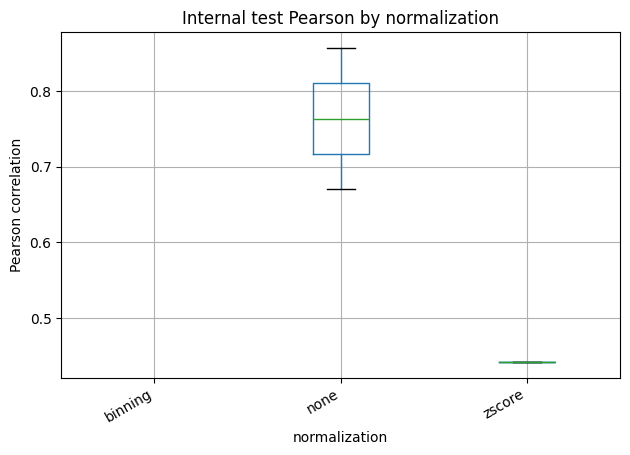

<Figure size 800x400 with 0 Axes>

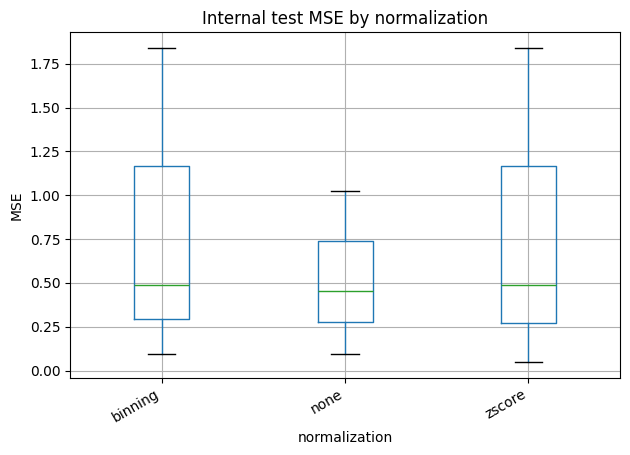

In [7]:
# Simple smoke-test plots
plot_df = summary.copy()

plt.figure(figsize=(8, 4))
plot_df.boxplot(column='test_pearson_corr', by='normalization')
plt.title('Internal test Pearson by normalization')
plt.suptitle('')
plt.ylabel('Pearson correlation')
plt.xticks(rotation=30, ha='right')
plt.tight_layout()
plt.show()

plt.figure(figsize=(8, 4))
plot_df.boxplot(column='test_mse', by='normalization')
plt.title('Internal test MSE by normalization')
plt.suptitle('')
plt.ylabel('MSE')
plt.xticks(rotation=30, ha='right')
plt.tight_layout()
plt.show()


In [8]:
# Inspect one final all-samples model artifact and use it for prediction on the same X matrix.
best_row = summary.sort_values('test_pearson_corr', ascending=False).iloc[0]
key = (best_row['protein'], best_row['normalization'])
res = results[key]
artifact = res['model_artifact']

print('Best smoke-test result:')
print(best_row.to_string())
print('Artifact keys:', sorted(artifact.keys()))
print('Selected feature examples:', artifact['selected_features'][:10])
print('Params:', artifact['params'])

pred = predict_with_artifact(artifact, X.iloc[:5])
display(pred.to_frame('saved_model_prediction'))


Best smoke-test result:
protein                                                                 A2M
normalization                                                          none
test_mse                                                           1.024559
test_pearson_corr                                                  0.856993
test_cosine_similarity                                             0.839075
train_n                                                                  32
test_n                                                                    8
selected_features                                                        50
nonzero_coefficients                                                     29
best_params               {'alpha': 0.1, 'l1_ratio': 0.1, '_cv_mse': 1.0...
Artifact keys: ['artifact_kind', 'coef_nonzero_count', 'fit_intercept', 'intercept', 'model', 'n_training_samples_final_model', 'normalization', 'normalizer', 'params', 'params_with_cv_metadata', 'protein', 'selected

,saved_model_prediction
samples,
MDAMB468_BREAST,-0.390506
SH4_SKIN,0.799424
AU565_BREAST,-0.744058
KMRC1_KIDNEY,0.898354
CAL51_BREAST,0.230250
